
# IoTShield — 05: Bot ve DDoS neden ayrılamıyor? (overlap kanıtı)
**SE3513 · WP-D2 · ASEADOS-SDN-IoT**

Soru: Bozuk satırlarda (`Protocol == 0`) Bot ve DDoS'u ayıran bilgi ne kadar? EDA'da (01, Bölüm 8.2) bu satırların çoğunda F_timing vektörünün tamamen akış süresinden belirlendiğini gördük. Burada bunu dört yoldan ölçüyoruz:
1. Sadece süre ile ve F_timing ile model (9.1), eğitimi dengeleyerek (9.2)
2. Süre dağılımı (9.3) ve PCA görünümü (9.4)
3. kNN komşuluk oranı (9.5)
4. Çelişkili satırlar: doğruluğun üst sınırı (9.6)

Tüm model sonuçları `src/cv.run_cv` ile, oturum gruplu katlarla (`get_folds`) ve `../reports/results_overlap.csv`'ye yazılır.



## 0. Kurulum
Yollar, sabitler ve ortak fonksiyonlar `src/`'den.


In [1]:

import os
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

sys.path.append('..')
from src.config import DATA_PATH, RANDOM_STATE, F_TIMING, FEATURE_FAMILIES
from src.preprocessing import clean
from src.cv import get_folds, print_fold_table, run_cv, compute_metrics, make_groups
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style='whitegrid')
CLASS_ORDER = ['Benign', 'Dos', 'DDoS', 'Bot', 'Prob']
OVERLAP_CSV = '../reports/results_overlap.csv'
FIG_DIR = '../reports/figures/'



## 1. Veri: bozuk satırlar ve bozuk Bot + DDoS alt kümesi
`clean()` sonrası veriden sadece bozuk satırlar (`broken == True`). Bot ve DDoS'un tamamı bozuk; 9.1–9.2 bu iki sınıfın satırlarıyla, 9.3–9.5 bozuk satırların 5 sınıfıyla çalışır.


In [2]:

data = clean(pd.read_csv(DATA_PATH, low_memory=False))
data['session'] = make_groups(data)   # recording sessions = CV groups (used in 9.5)
broken = data[data['broken']].reset_index(drop=True)
bot_ddos = broken[broken['Label'].isin(['Bot', 'DDoS'])].reset_index(drop=True)

print('bozuk satırlar:', broken.shape)
display(broken['Label'].value_counts().reindex(CLASS_ORDER))
print('bozuk Bot + DDoS:', bot_ddos.shape)
display(bot_ddos['Label'].value_counts())

# Bot and DDoS have no healthy rows, so this subset is the whole of both classes
assert (data['Label'] == 'Bot').sum() == (bot_ddos['Label'] == 'Bot').sum()
assert (data['Label'] == 'DDoS').sum() == (bot_ddos['Label'] == 'DDoS').sum()


clean: dropped 70 rows with inf/NaN
clean: clipped negative values to 0 in 427 rows


clean: removed 29930 duplicate rows (features + label)
clean: final shape (427044, 63)


bozuk satırlar: (124421, 64)


Label
Benign    41937
Dos       15693
DDoS      50269
Bot        8957
Prob       7565
Name: count, dtype: int64

bozuk Bot + DDoS: (59226, 64)


Label
DDoS    50269
Bot      8957
Name: count, dtype: int64


## 2. Katlar (Bot + DDoS alt kümesi)
`get_folds` oturumları sınıf içinde katlara dağıtır: Bot'un 3 oturumu, her katta bir tane. Sonuç dosyası her çalıştırmada sıfırdan yazılır (`run_cv` satır ekler; tekrar çalıştırmada aynı satırlar iki kez yazılmasın).

Not (Kural 3): bu alt kümede sağlam satır yok. Bu yüzden `macro_f1_clean` boş (NaN), "tüm" ve "bozuk" skor aynıdır. F1, Bot ve DDoS olmak üzere iki sınıfın ortalamasıdır.


In [3]:

if os.path.exists(OVERLAP_CSV):
    os.remove(OVERLAP_CSV)

folds = get_folds(bot_ddos)
fold_table = print_fold_table(bot_ddos, folds)


Test kısmındaki satır sayıları (sınıf × kat):
       fold_0  fold_1  fold_2
Label                        
DDoS    23953   10599   15717
Bot      1757    2585    4615
Test kısmındaki oturum sayıları (sınıf × kat):
       fold_0  fold_1  fold_2
Label                        
Bot         1       1       1
DDoS        1       1       2



## 3. (9.1) Sadece süre ile Bot vs DDoS
Bozuk Bot + DDoS satırlarında, aynı katlarla iki model (LightGBM, varsayılan parametreler):
- **(a)** sadece `Flow Duration` (1 sütun; config'de `FEATURE_FAMILIES['duration']`)
- **(b)** F_timing (15 sütun)

(a) ile (b) yakın çıkarsa, F_timing'in 15 sütunu bu satırlarda büyük ölçüde aynı bilgiyi (süreyi) taşıyor demektir.


In [4]:

DURATION_ONLY = FEATURE_FAMILIES['duration']   # ['Flow Duration']


def lgbm_pipeline():
    """Returns the fixed experiment model (CLAUDE.md rule 5) inside an imblearn Pipeline."""
    return Pipeline([('model', LGBMClassifier(random_state=RANDOM_STATE, verbose=-1))])


results = []
oofs = {}
for feats, set_name, experiment in [(DURATION_ONLY, 'duration_only', 'D2-9.1a'),
                                    (F_TIMING, 'F_timing', 'D2-9.1b')]:
    print(f'\n=== {experiment} | {set_name} ===')
    row, cm, oof = run_cv(lgbm_pipeline(), bot_ddos, feats, OVERLAP_CSV, experiment=experiment,
                          sampler='none', feature_set=set_name, folds=folds, note='broken Bot+DDoS only')
    results.append(row)
    oofs[experiment] = oof
    display(cm.loc[['DDoS', 'Bot'], ['DDoS', 'Bot']])



=== D2-9.1a | duration_only ===
Kat 0


  eğitim: 33284 satır (çelişki atılan: 232 ) | test: 25710 | fit: 0.3 sn
Kat 1


  eğitim: 45780 satır (çelişki atılan: 262 ) | test: 13184 | fit: 0.2 sn
Kat 2


  eğitim: 38882 satır (çelişki atılan: 12 ) | test: 20332 | fit: 0.2 sn


Kat F1'leri: [0.5395 0.4652 0.4563] → 0.487 ± 0.0457
CSV'ye eklendi: ../reports/results_overlap.csv


,DDoS,Bot
DDoS,48641,1628
Bot,8557,400


... (2 outputs left out)

  eğitim: 45896 satır (çelişki atılan: 146 ) | test: 13184 | fit: 0.3 sn
Kat 2


  eğitim: 38882 satır (çelişki atılan: 12 ) | test: 20332 | fit: 0.2 sn


Kat F1'leri: [0.5485 0.4844 0.4528] → 0.4952 ± 0.0488
CSV'ye eklendi: ../reports/results_overlap.csv


,DDoS,Bot
DDoS,47759,2510
Bot,8372,585



Yan yana: ortalama ± std macro F1 (Bot ve DDoS'un F1 ortalaması), sınıf recall'ları, Bot↔DDoS karışma oranı; altta kat bazında macro F1 (OOF tahminlerinden `compute_metrics` ile).


In [5]:

SHOW_COLS = ['experiment', 'feature_set', 'sampler', 'macro_f1_mean', 'macro_f1_std',
             'recall_DDoS', 'recall_Bot', 'bot_ddos_confusion']
display(pd.DataFrame(results)[SHOW_COLS].round(3))

labels = bot_ddos['Label'].to_numpy()
is_broken = bot_ddos['broken'].to_numpy()
fold_rows = []
for experiment, oof in oofs.items():
    predictions = oof.to_numpy()
    for fold_no, (train_idx, test_idx) in enumerate(folds):
        m = compute_metrics(labels[test_idx], predictions[test_idx], is_broken[test_idx])
        fold_rows.append({'experiment': experiment, 'kat': fold_no, 'macro_f1': round(m['macro_f1'], 3),
                          'recall_Bot': round(m['recall_Bot'], 3), 'recall_DDoS': round(m['recall_DDoS'], 3)})
display(pd.DataFrame(fold_rows).pivot(index='kat', columns='experiment'))


,experiment,feature_set,sampler,macro_f1_mean,macro_f1_std,recall_DDoS,recall_Bot,bot_ddos_confusion
0,D2-9.1a,duration_only,none,0.487,0.046,0.968,0.045,0.172
1,D2-9.1b,F_timing,none,0.495,0.049,0.950,0.065,0.184


macro_f1         recall_Bot         recall_DDoS        
experiment  D2-9.1a D2-9.1b    D2-9.1a D2-9.1b     D2-9.1a D2-9.1b
kat                                                               
0             0.539   0.549      0.086   0.093       0.977   0.981
1             0.465   0.484      0.025   0.044       0.983   0.987
2             0.456   0.453      0.040   0.067       0.943   0.877


**Bulgu (9.1):**
- Sadece süre ile macro F1 **0,487 ± 0,046**, F_timing (15 sütun) ile **0,495 ± 0,049**. Fark 0,008; katlar arası std'nin (≈ 0,05) içinde. Kat bazında da iki model birbirine yakın (0,539 / 0,549, 0,465 / 0,484, 0,456 / 0,453).
- Bu veride ve bu modelle, F_timing'in diğer 14 sütunu süreye ölçülebilir bir bilgi eklemiyor. EDA 8.2'deki bulguyla uyumlu: bu satırların çoğunda F_timing vektörü süreden belirleniyor.
- İki modelde de Bot recall'u çok düşük (0,045 / 0,065): Bot satırlarının çoğu DDoS tahmin ediliyor. Macro F1'in 0,5 civarında olması büyük ölçüde DDoS'un yüksek, Bot'un çok düşük F1'inden geliyor.
- Not: `results_overlap.csv`'de bu alt kümede olmayan sınıfların recall sütunları (`recall_Benign`, `recall_Dos`, `recall_Prob`) 0 yazılıyor; bunlar ölçüm değil, "sınıf yok" anlamında okunmalı.



## 4. (9.2) Dengeleme testi: eğitim katında Bot : DDoS = 1 : 1
9.1(b) ile aynı model, aynı katlar ve aynı F_timing sütunları. Tek fark: eğitim katında DDoS satırları rastgele azaltılarak Bot sayısına indirilir (`RandomUnderSampler`). Sampler Pipeline içinde, yani sadece eğitim katında çalışır; test katına dokunmaz (Kural 4).

Dengeleme F1'i az değiştiriyorsa, sorun örnek sayısından çok satırlardaki bilgide demektir.


In [6]:

balanced_pipe = Pipeline([('sampler', RandomUnderSampler(random_state=RANDOM_STATE)),
                          ('model', LGBMClassifier(random_state=RANDOM_STATE, verbose=-1))])

print('=== D2-9.2 | F_timing | RandomUnderSampler ===')
row, cm, oof = run_cv(balanced_pipe, bot_ddos, F_TIMING, OVERLAP_CSV, experiment='D2-9.2',
                      sampler='RandomUnderSampler', feature_set='F_timing', folds=folds,
                      note='broken Bot+DDoS only; train fold balanced 1:1')
results.append(row)
oofs['D2-9.2'] = oof
display(cm.loc[['DDoS', 'Bot'], ['DDoS', 'Bot']])


=== D2-9.2 | F_timing | RandomUnderSampler ===
Kat 0


  eğitim: 33388 satır (çelişki atılan: 128 ) | test: 25710 | fit: 0.3 sn
Kat 1


  eğitim: 45896 satır (çelişki atılan: 146 ) | test: 13184 | fit: 0.3 sn
Kat 2


  eğitim: 38882 satır (çelişki atılan: 12 ) | test: 20332 | fit: 0.2 sn


Kat F1'leri: [0.5079 0.5096 0.5053] → 0.5076 ± 0.0022
CSV'ye eklendi: ../reports/results_overlap.csv


,DDoS,Bot
DDoS,29345,20924
Bot,3094,5863



9.1(b) ile 9.2 yan yana: tüm katlar ve kat bazında.


In [7]:

compare = pd.DataFrame(results)
display(compare.loc[compare['experiment'].isin(['D2-9.1b', 'D2-9.2']), SHOW_COLS].round(3))

predictions = oofs['D2-9.2'].to_numpy()
for fold_no, (train_idx, test_idx) in enumerate(folds):
    m = compute_metrics(labels[test_idx], predictions[test_idx], is_broken[test_idx])
    fold_rows.append({'experiment': 'D2-9.2', 'kat': fold_no, 'macro_f1': round(m['macro_f1'], 3),
                      'recall_Bot': round(m['recall_Bot'], 3), 'recall_DDoS': round(m['recall_DDoS'], 3)})
fold_table = pd.DataFrame(fold_rows)
display(fold_table[fold_table['experiment'].isin(['D2-9.1b', 'D2-9.2'])].pivot(index='kat', columns='experiment'))


,experiment,feature_set,sampler,macro_f1_mean,macro_f1_std,recall_DDoS,recall_Bot,bot_ddos_confusion
1,D2-9.1b,F_timing,none,0.495,0.049,0.950,0.065,0.184
2,D2-9.2,F_timing,RandomUnderSampler,0.508,0.002,0.584,0.655,0.406


macro_f1        recall_Bot        recall_DDoS       
experiment  D2-9.1b D2-9.2    D2-9.1b D2-9.2     D2-9.1b D2-9.2
kat                                                            
0             0.549  0.508      0.093  0.760       0.981  0.653
1             0.484  0.510      0.044  0.657       0.987  0.526
2             0.453  0.505      0.067  0.613       0.877  0.517


**Bulgu (9.2):**
- Dengeleme macro F1'i **0,495 ± 0,049 → 0,508 ± 0,002** yapıyor (+0,012; 9.1(b)'nin std'sinin içinde).
- Değişen şey hata türü: Bot recall'u 0,065 → **0,655**, DDoS recall'u 0,950 → **0,584**. Model artık daha çok Bot diyor, ama DDoS satırlarının 20.924'ü de Bot tahmin ediliyor; Bot tahminlerinin sadece %22'si doğru (5.863 / 26.787). Bot ↔ DDoS karışma oranı 0,184 → 0,406.
- Yani dengeleme iki sınıf arasındaki sınırı kaydırıyor, ayrımı iyileştirmiyor. Bu ölçüm, sorunun örnek sayısından çok bu satırlardaki bilgide olduğu yorumuyla uyumlu.
- Karşılaştırma raporundaki 0,631 → 0,705 sonucu rastgele CV ile ve farklı bir kurulumla alınmıştı; buradaki gruplu CV sayılarıyla doğrudan karşılaştırılamaz.



## 5. (9.3) Süre dağılımı: bozuk satırlarda log1p(Flow Duration)
Sol: Bot ve DDoS üst üste. Sağ: bozuk satırlardaki 5 sınıfın hepsi. Her eğri kendi sınıfının içinde normalize (`common_norm=False`), yani sınıf büyüklüğü eğrinin yüksekliğini etkilemez. Altta, sınıf başına süre çeyrekleri (saniye).


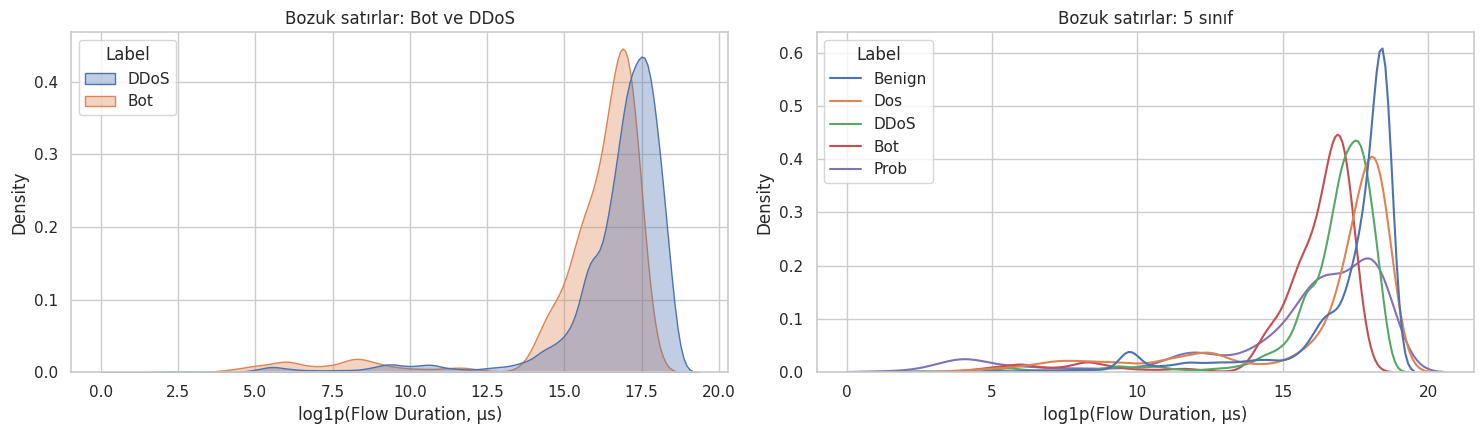

,Q1_sn,medyan_sn,Q3_sn
Label,,,
Benign,19.26,66.89,104.94
Dos,10.27,50.56,80.78
DDoS,12.18,27.50,48.63
Bot,5.60,15.43,24.56
Prob,2.38,15.45,62.04


In [8]:

MICROSECONDS_PER_SECOND = 1_000_000

broken = broken.copy()
broken['log_duration'] = np.log1p(broken['Flow Duration'])
bot_ddos_broken = broken[broken['Label'].isin(['Bot', 'DDoS'])]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.kdeplot(data=bot_ddos_broken, x='log_duration', hue='Label', hue_order=['DDoS', 'Bot'],
            common_norm=False, clip=(0, None), fill=True, alpha=0.35, ax=axes[0])
axes[0].set_title('Bozuk satırlar: Bot ve DDoS')
sns.kdeplot(data=broken, x='log_duration', hue='Label', hue_order=CLASS_ORDER,
            common_norm=False, clip=(0, None), ax=axes[1])
axes[1].set_title('Bozuk satırlar: 5 sınıf')
for ax in axes:
    ax.set_xlabel('log1p(Flow Duration, µs)')
plt.tight_layout()
plt.savefig(FIG_DIR + 'overlap_duration_kde.png', dpi=150, bbox_inches='tight'); plt.show()

duration_seconds = broken['Flow Duration'] / MICROSECONDS_PER_SECOND
quartiles = duration_seconds.groupby(broken['Label']).quantile([0.25, 0.5, 0.75]).unstack()
quartiles.columns = ['Q1_sn', 'medyan_sn', 'Q3_sn']
display(quartiles.reindex(CLASS_ORDER).round(2))



**Bulgu (9.3):**
- Bozuk satırlarda Bot ve DDoS'un süre dağılımları büyük ölçüde üst üste. Bot biraz daha kısa: medyan **15,4 sn** (Q1–Q3: 5,6–24,6), DDoS medyan **27,5 sn** (12,2–48,6). Bot'un çeyrekler arası aralığının büyük kısmı DDoS'unkinin içinde.
- 9.1'de sadece süre ile F_timing aynı F1'i verdiği için, bu satırlarda iki sınıfı ayırmak için elde kalan bilgi büyük ölçüde bu tek dağılım; ve bu dağılımda iki sınıf örtüşüyor.
- Sağ panelde diğer bozuk sınıfların yoğunluğu da aynı bölgede (log1p 15–18,5, yani yaklaşık 3–110 sn). Prob'un dağılımı daha geniş; Benign ve Dos'un tepesi daha uzun sürelerde.



## 6. (9.4) PCA görünümü: 15 özelliğe birlikte bakınca da örtüşme sürüyor mu?
Bozuk satırlardan her sınıftan 2.000 örnek (`random_state=42`). F_timing sütunlarına sırayla log1p → StandardScaler → PCA(2). Bu bir görselleştirme, model değil; scaler ve PCA sadece bu örnekte fit edilir. Aynı örnek ve aynı ölçeklenmiş uzay 9.5'te (kNN) de kullanılır.


In [9]:

SAMPLE_PER_CLASS = 2_000

parts = []
for label in CLASS_ORDER:
    class_rows = broken[broken['Label'] == label]
    parts.append(class_rows.sample(n=SAMPLE_PER_CLASS, random_state=RANDOM_STATE))
sample = pd.concat(parts).reset_index(drop=True)
print('örnek:', sample.shape)
display(sample['Label'].value_counts().reindex(CLASS_ORDER))

# log1p needs values >= 0; clean() clips negative timing values to 0
assert (sample[F_TIMING] >= 0).all().all()
Z = StandardScaler().fit_transform(np.log1p(sample[F_TIMING]))
sample_labels = sample['Label'].to_numpy()

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pc = pca.fit_transform(Z)
explained = pca.explained_variance_ratio_
print('açıklanan varyans: PC1 = %.3f, PC2 = %.3f, toplam = %.3f' % (explained[0], explained[1], explained.sum()))

# rows with exactly 1 forward + 1 backward packet (EDA 01, section 8.2): their F_timing vector depends on duration only
is_one_one = ((sample['Tot Fwd Pkts'] == 1) & (sample['Tot Bwd Pkts'] == 1)).to_numpy()
one_one_share = pd.Series(is_one_one).groupby(sample['Label']).mean().reindex(CLASS_ORDER) * 100
print('örnekte 1/1 paketli satır payı (%):'); display(one_one_share.round(1))
print('1/1 satırlarda PC1 aralığı: %.2f – %.2f' % (pc[is_one_one, 0].min(), pc[is_one_one, 0].max()))

örnek: (10000, 65)


Label
Benign    2000
Dos       2000
DDoS      2000
Bot       2000
Prob      2000
Name: count, dtype: int64

açıklanan varyans: PC1 = 0.443, PC2 = 0.266, toplam = 0.709
örnekte 1/1 paketli satır payı (%):


Label
Benign    65.3
Dos       92.0
DDoS      86.4
Bot       92.6
Prob      38.4
dtype: float64

1/1 satırlarda PC1 aralığı: -1.42 – -1.34



Sol: sadece Bot ve DDoS (diğer sınıflar gri arka plan). Sağ: 5 sınıf.


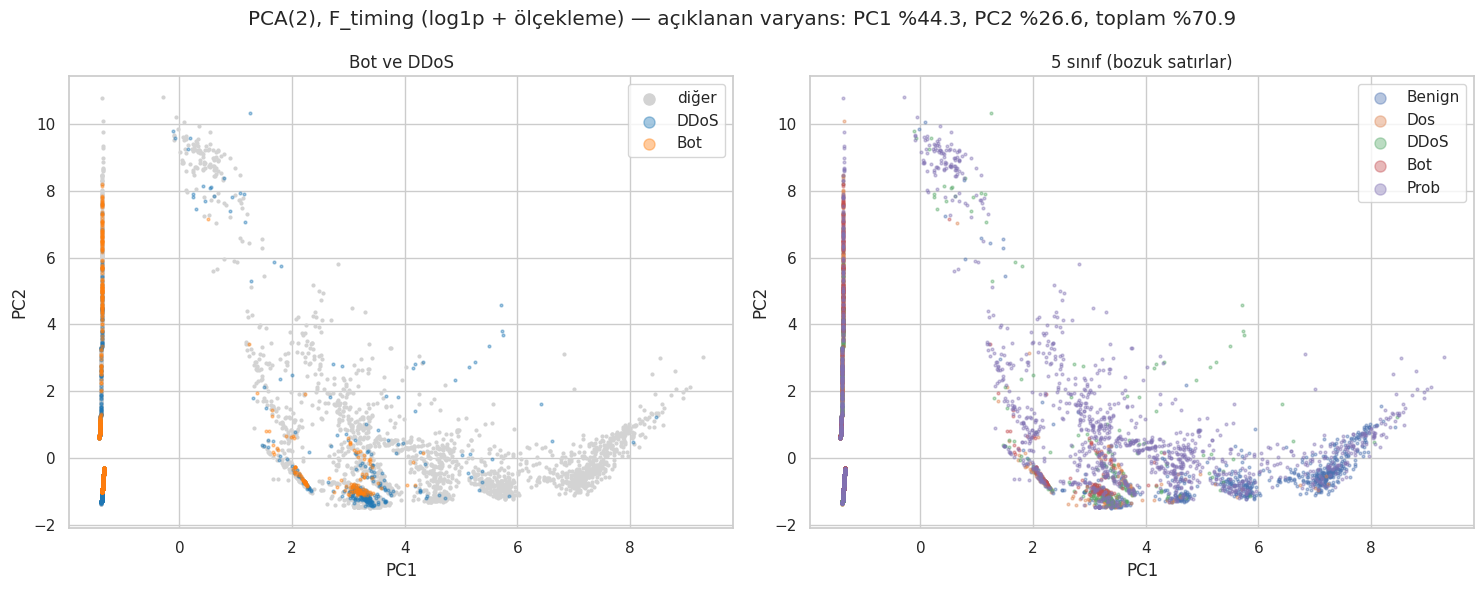

In [10]:

title_variance = f'PCA(2), F_timing (log1p + ölçekleme) — açıklanan varyans: PC1 %{explained[0]*100:.1f}, PC2 %{explained[1]*100:.1f}, toplam %{explained.sum()*100:.1f}'
is_bot_or_ddos = np.isin(sample_labels, ['Bot', 'DDoS'])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(pc[~is_bot_or_ddos, 0], pc[~is_bot_or_ddos, 1], s=4, color='lightgrey', label='diğer')
for label, color in [('DDoS', 'tab:blue'), ('Bot', 'tab:orange')]:
    in_class = sample_labels == label
    axes[0].scatter(pc[in_class, 0], pc[in_class, 1], s=4, alpha=0.4, color=color, label=label)
axes[0].set_title('Bot ve DDoS')
for label in CLASS_ORDER:
    in_class = sample_labels == label
    axes[1].scatter(pc[in_class, 0], pc[in_class, 1], s=4, alpha=0.4, label=label)
axes[1].set_title('5 sınıf (bozuk satırlar)')
for ax in axes:
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(markerscale=4)
fig.suptitle(title_variance)
plt.tight_layout()
plt.savefig(FIG_DIR + 'overlap_pca.png', dpi=150, bbox_inches='tight'); plt.show()



**Bulgu (9.4):**
- İki bileşen F_timing'deki varyansın **%70,9**'unu açıklıyor (PC1 %44,3, PC2 %26,6).
- PC1 ≈ −1,4'teki dikey çizgi **1 ileri + 1 geri paketli satırlar**: örnekteki bu satırların hepsi PC1 = −1,42 … −1,34 aralığında. Örnekte Bot'un %92,6'sı, DDoS'un %86,4'ü, Dos'un %92,0'ı bu çizgide. Bu satırlarda 15 boyutlu vektör tek bir sayıya (süreye) bağlı olduğu için tek boyutlu bir eğriye düşüyor (EDA 8.2 ile uyumlu).
- Bot ve DDoS bu çizgide aynı aralıkta; çizginin dışındaki az sayıdaki noktada da aynı kümelerde karışık duruyorlar. 15 özelliğe birlikte bakıldığında da örtüşme sürüyor.
- Okuma notu: noktalar üst üste çizildiği için çizgi üzerinde sonradan çizilen sınıf (solda Bot, sağda Prob) altındakini örtüyor. Grafik örtüşmeyi gösterir ama ne kadar olduğunu ölçmez; ölçü 9.5'teki kNN oranı.



## 7. (9.5) kNN komşuluk oranı
9.4'teki aynı 10.000 noktalık örnek ve aynı ölçeklenmiş F_timing uzayı (`Z`, PCA'dan önce, 15 boyut). Her noktanın en yakın 10 komşusuna bakılır; nokta kendi komşusu sayılmaz. Tablo: satır = noktanın gerçek sınıfı, sütun = komşularının sınıfı (%). Her sınıftan eşit sayıda nokta olduğu için, sınıflar tamamen karışık olsaydı her hücre yaklaşık %20 olurdu.


In [11]:

N_NEIGHBORS = 10

# kneighbors() without X returns the neighbours of every fitted point and does not count the
# point itself (same as "skip the first neighbour" in the plan, but also correct when there are
# duplicate points at distance 0).
nn = NearestNeighbors(n_neighbors=N_NEIGHBORS).fit(Z)
_, neighbor_idx = nn.kneighbors()
neighbor_labels = sample_labels[neighbor_idx]          # shape: (10000, 10)
assert neighbor_labels.shape == (len(sample_labels), N_NEIGHBORS)

share_rows = {}
for label in CLASS_ORDER:
    rows_of_class = neighbor_labels[sample_labels == label]
    shares = {}
    for neighbor_class in CLASS_ORDER:
        shares[neighbor_class] = (rows_of_class == neighbor_class).mean() * 100
    share_rows[label] = shares
neighbor_share = pd.DataFrame(share_rows).T[CLASS_ORDER]
neighbor_share.index.name = 'nokta sınıfı'
display(neighbor_share.round(1))

bot_to_ddos = neighbor_share.loc['Bot', 'DDoS']
ddos_to_bot = neighbor_share.loc['DDoS', 'Bot']
print(f'Bot noktalarının komşuları içinde DDoS payı: %{bot_to_ddos:.1f} | DDoS noktalarının komşuları içinde Bot payı: %{ddos_to_bot:.1f}')


,Benign,Dos,DDoS,Bot,Prob
nokta sınıfı,,,,,
Benign,40.1,20.4,16.8,9.7,13.1
Dos,19.9,39.2,18.5,12.0,10.4
DDoS,16.5,18.4,30.7,23.0,11.5
Bot,9.0,11.4,22.1,47.9,9.7
Prob,14.6,9.8,10.4,9.7,55.6


Bot noktalarının komşuları içinde DDoS payı: %22.1 | DDoS noktalarının komşuları içinde Bot payı: %23.0



**Oturum etkisi:** Örnek rastgele seçildiği için, bir noktanın komşuları çoğu zaman **aynı kayıt oturumundan** gelir. Aynı oturumun akışları birbirine çok benzer, bu da "aynı sınıf" oranını yükseltir; oysa modeller gruplu CV'de hiç görmedikleri oturumlarda test ediliyor (9.1–9.2). Bu yüzden Bot ve DDoS için ayrıca: (1) aynı sınıftan komşuların ne kadarı aynı oturumdan, (2) sadece **kendi oturumu dışındaki** komşulara bakınca sınıf payları. Oturumlar `make_groups` ile tam veride hesaplandı (CV gruplarıyla aynı).


In [12]:

sample_sessions = sample['session'].to_numpy()
neighbor_sessions = sample_sessions[neighbor_idx]

session_rows = []
for label in ['Bot', 'DDoS']:
    is_label = sample_labels == label
    labels_of_neighbors = neighbor_labels[is_label]
    same_session = neighbor_sessions[is_label] == sample_sessions[is_label][:, None]
    same_class = labels_of_neighbors == label
    other_session = ~same_session
    session_rows.append({
        'nokta sınıfı': label,
        'aynı sınıf komşu %': round(same_class.mean() * 100, 1),
        'bunların aynı oturumdan olanı %': round((same_class & same_session).sum() / same_class.sum() * 100, 1),
        'oturum dışı komşularda Bot %': round(((labels_of_neighbors == 'Bot') & other_session).sum() / other_session.sum() * 100, 1),
        'oturum dışı komşularda DDoS %': round(((labels_of_neighbors == 'DDoS') & other_session).sum() / other_session.sum() * 100, 1),
    })
display(pd.DataFrame(session_rows).set_index('nokta sınıfı'))


,aynı sınıf komşu %,bunların aynı oturumdan olanı %,oturum dışı komşularda Bot %,oturum dışı komşularda DDoS %
nokta sınıfı,,,,
Bot,47.9,59.0,27.4,30.7
DDoS,30.7,41.7,26.3,20.5



**Bulgu (9.5):**
- Bot noktalarının en yakın 10 komşusunun **%22,1'i DDoS**; DDoS noktalarının komşularının **%23,0'ü Bot**. Sınıflar tamamen karışık olsaydı beklenen değer %20 olurdu. DDoS noktalarının komşularında Bot payı (%23,0), DDoS payına (%30,7) yakın.
- Bot noktalarının komşularının %47,9'u yine Bot; ama bu Bot komşularının **%59'u aynı kayıt oturumundan**. Sadece kendi oturumu dışındaki komşulara bakınca Bot noktalarının komşularında **DDoS (%30,7) Bot'tan (%27,4) fazla**; DDoS noktalarında Bot %26,3, DDoS %20,5.
- Yani "aynı sınıf" benzerliğinin büyük kısmı aynı oturumdan geliyor; başka oturumlara bakınca Bot ve DDoS bu uzayda birbirinden ayırt edilir görünmüyor. Bu, 9.1–9.2'de gruplu CV'de (test oturumları eğitimde hiç yok) Bot'un ayrılamamasıyla uyumlu.
- Ölçüm notu: 10.000 noktalık tek bir örnek (`random_state=42`), F_timing, log1p + ölçekleme, Öklid uzaklığı.



## 8. (9.6) Üst sınır: F_timing uzayında çelişkili satırlar
Çelişkili satır: F_timing değerleri birebir aynı, etiketi farklı satırlar. Aynı özellik vektörü farklı etiket taşıyor; bu satırlarda doğruluğun bir üst sınırı var. Üç sayım:
1. **`clean()` verisinde** (tüm sınıflar): `run_cv`'nin (`drop_conflicts`) eğitim katından attığı tanım.
2. Aynı veri, F_timing'de tekrarlar da silinince (karşılaştırma raporundaki 4.550'ye en yakın tanım).
3. Sadece **Bot ↔ DDoS** çakışmaları: bir Bot satırı ile bir DDoS satırının birebir aynı vektörü paylaşması.


In [13]:

def conflict_summary(frame, name):
    """Counts rows whose F_TIMING vector carries more than one label.
    Returns a dict: conflicting rows, distinct vectors, Bot rows among them and their share of Bot."""
    labels_per_vector = frame.groupby(F_TIMING)['Label'].transform('nunique')
    is_conflict = labels_per_vector > 1
    is_bot = frame['Label'] == 'Bot'
    n_bot_class = is_bot.sum()
    n_bot_conflict = (is_conflict & is_bot).sum()
    return {'tanım': name, 'çelişkili_satır': int(is_conflict.sum()),
            'farklı_vektör': len(frame.loc[is_conflict, F_TIMING].drop_duplicates()),
            'Bot_satır': int(n_bot_conflict), 'Bot_sınıfının_%': round(n_bot_conflict / n_bot_class * 100, 1)}


deduplicated = data.drop_duplicates(subset=F_TIMING + ['Label'])
bot_and_ddos_rows = data[data['Label'].isin(['Bot', 'DDoS'])]

conflict_table = pd.DataFrame([
    conflict_summary(data, '1) clean() verisi (run_cv tanımı)'),
    conflict_summary(deduplicated, '2) + F_timing tekrarları silinince'),
    conflict_summary(bot_and_ddos_rows, '3) sadece Bot ↔ DDoS çakışmaları'),
]).set_index('tanım')
display(conflict_table)
print('Bot satırı (clean):', (data['Label'] == 'Bot').sum())


,çelişkili_satır,farklı_vektör,Bot_satır,Bot_sınıfının_%
tanım,,,,
1) clean() verisi (run_cv tanımı),7951,1970,402,4.5
2) + F_timing tekrarları silinince,4520,1970,402,4.5
3) sadece Bot ↔ DDoS çakışmaları,208,104,104,1.2


Bot satırı (clean): 8957



**Bulgu (9.6):**
- `clean()` verisinde F_timing uzayında **7.951 çelişkili satır** var (1.970 farklı vektör); bunların 402'si Bot (Bot sınıfının %4,5'i). F_timing tekrarları silinince 4.520 satır (karşılaştırma raporundaki 4.550'ye en yakın tanım).
- Bot ile DDoS'un **birebir aynı** vektörü paylaştığı satırlar az: 104 Bot satırı (Bot'un **%1,2'si**). Karşılaştırma raporundaki "Bot'un %1,5'i" denediğimiz tanımların hiçbiriyle birebir çıkmadı; en yakını bu.
- Bağlantı: birebir çakışma, Bot/DDoS ayrımına sadece küçük bir üst sınır koyuyor. 9.1–9.5'te görülen ayrılamama büyük ölçüde birebir aynı satırlardan değil, **aynı bölgede örtüşen süre dağılımlarından** (9.3) ve oturum dışı komşuların karışık olmasından (9.5) geliyor.
